# Experiment 05: Tuned lgbm_building

Card: [exp05_tuned.md](../../experiments/exp05_tuned.md)


In [1]:
import os
import sys
from time import perf_counter, strftime

import lightgbm as lgb
import matplotlib.pyplot as plt
import mlflow
import numpy as np
import pandas as pd

sys.path.insert(0, "../../..")  # the ashrae package lives in the homework folder
from ashrae.config import FOLDS, METERS, MLFLOW_URI
from ashrae.metrics import rmsle, rmsle_by_meter
from ashrae.tracking import log_run
from ashrae.tuning import make_folds, progress

SMOKE = os.environ.get("SMOKE") == "1"
LEARNING_RATE = 0.1
if SMOKE:
    EXPERIMENT = "ashrae-baseline-tuning-smoke"
    TUNING_SESSION = None  # the latest exp03 smoke session
    FOLD_NAMES = list(FOLDS)[:2]
    N_TRAIN, N_VAL = 20_000, 5_000
    BASE_LEAVES = 15
    FIGURE = None
else:
    EXPERIMENT = "ashrae-baseline-tuning"
    TUNING_SESSION = "2026-10-11 12:25:43"  # exp03 and exp04 trials
    FOLD_NAMES = list(FOLDS)
    N_TRAIN, N_VAL = 2_000_000, 500_000  # exp02: more rows don't help
    BASE_LEAVES = 127
    FIGURE = "../../figures/exp05_tuned.png"
SESSION = strftime("%Y-%m-%d %H:%M:%S")  # tag shared by this execution's runs
BASE = f"{BASE_LEAVES} leaves"
TRIAL_ONLY = [
    "learning_rate",
    "max_trees",
    "patience",
    "n_train",
    "n_val",
]  # logged by run_trial, not model settings

mlflow.set_tracking_uri(MLFLOW_URI)
mlflow.set_experiment(EXPERIMENT)
client = mlflow.MlflowClient()

/Users/lupaskodmitro/FuckIT/Machine Learning/Deep Learning Homeworks/Homework 1 MLP/.venv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Tuned settings


In [ ]:
trials = mlflow.search_runs(experiment_names=[EXPERIMENT])
if TUNING_SESSION is None:
    TUNING_SESSION = trials[trials["tags.stage"] == "A"]["tags.session"].max()
# Plain BASE leaves: exp04 found no regularization helps
row = trials[
    (trials["tags.session"] == TUNING_SESSION) & (trials["tags.trial"] == BASE)
].iloc[0]


def number(value):
    return int(value) if value.lstrip("-").isdigit() else float(value)


best_params = {
    c.removeprefix("params."): number(row[c])
    for c in trials.columns
    if c.startswith("params.")
    and c.removeprefix("params.") not in TRIAL_ONLY
    and pd.notna(row[c])
}
best_trees = int(row["metrics.trial_trees"])
tuned = {"learning_rate": LEARNING_RATE, **best_params, "n_estimators": best_trees}
print(f"Tuned: {BASE}, {tuned}")

Tuned: 127 leaves, {'learning_rate': 0.1, 'num_leaves': 127, 'n_estimators': 1736}


## Final model


In [3]:
folds = make_folds({f: FOLDS[f] for f in FOLD_NAMES}, N_TRAIN, N_VAL)
for fold, d in folds.items():
    start = perf_counter()
    # Fixed tree count from the trials, so no early stopping here
    model = lgb.LGBMRegressor(**tuned, metric="rmse", random_state=0, verbose=-1).fit(
        d["X_train"],
        d["y_train"],
        eval_X=(d["X_val"],),
        eval_y=(d["y_val"],),
        eval_names=["all"],
        callbacks=[progress(f"lgbm_building_tuned | {fold}", best_trees)],
    )
    train_seconds = perf_counter() - start
    pred = np.clip(model.predict(d["X_val"]), 0, None)
    metrics = {
        **rmsle_by_meter(d["y_val"], pred, d["meter"]),
        "val_rmsle_clean": rmsle(d["y_val"][d["clean"]], pred[d["clean"]]),
        "train_rmsle": rmsle(d["y_train"], model.predict(d["X_train"])),
        "train_seconds": train_seconds,
    }
    log_run(
        EXPERIMENT,
        f"lgbm_building_tuned | {fold}",
        params={
            **tuned,
            "n_train": N_TRAIN,
            "n_val": N_VAL,
            "from_trial": BASE,
            "tuning_session": TUNING_SESSION,
        },
        metrics=metrics,
        tags={
            "session": SESSION,
            "stage": "final",
            "fold": fold,
            "model": "lgbm_building_tuned",
            "notebook": "exp05_tuned",
        },
    )

fold data: 100%|██████████| 4/4 [00:05<00:00,  1.28s/fold]
lgbm_building_tuned | Jan–Mar: 100%|██████████| 1736/1736 [00:58<00:00, 29.49tree/s, best 1.4038 at 1532]            
lgbm_building_tuned | Apr–Jun: 100%|██████████| 1736/1736 [00:58<00:00, 29.59tree/s, best 1.2003 at 1718]            
lgbm_building_tuned | Jul–Sep: 100%|██████████| 1736/1736 [00:59<00:00, 29.40tree/s, best 1.0285 at 1731]            
lgbm_building_tuned | Oct–Dec: 100%|██████████| 1736/1736 [00:59<00:00, 29.40tree/s, best 1.0927 at 1046]            


## Results


,val_rmsle,val_rmsle_clean,train_rmsle,train_seconds
fold average,,,,
untuned,1.217,0.959,0.815,9.923
tuned,1.181,0.911,0.599,58.985


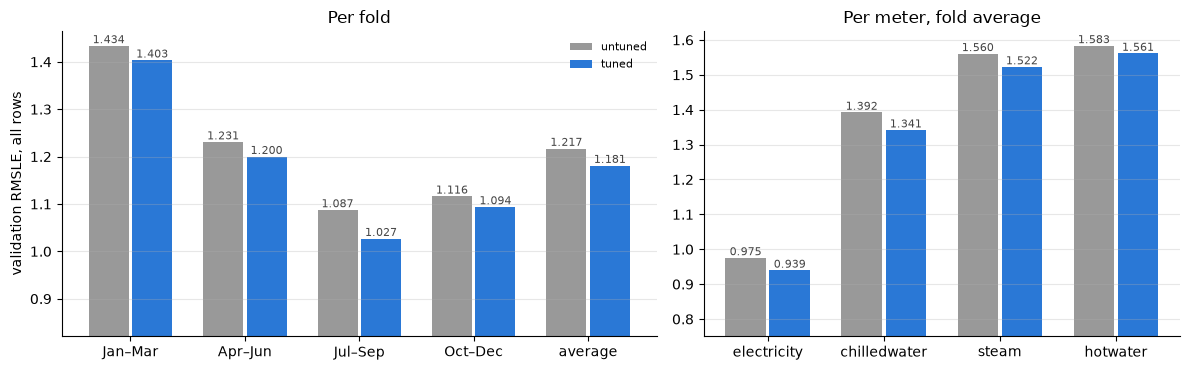

In [5]:
tuned_runs = mlflow.search_runs(
    experiment_names=[EXPERIMENT],
    filter_string=f"tags.stage = 'final' and tags.session = '{SESSION}'",
)
untuned_runs = mlflow.search_runs(
    experiment_names=["ashrae-baseline-building"],
    filter_string="tags.model = 'lgbm_building'",
)
untuned_runs = untuned_runs[
    untuned_runs["tags.session"] == untuned_runs["tags.session"].max()
]
untuned_runs = untuned_runs[untuned_runs["tags.fold"].isin(FOLD_NAMES)].assign(
    **{"tags.model": "untuned"}
)
final = pd.concat([untuned_runs, tuned_runs.assign(**{"tags.model": "tuned"})])
MODELS = ["untuned", "tuned"]

by_fold = final.pivot(
    index="tags.fold", columns="tags.model", values="metrics.val_rmsle"
).loc[FOLD_NAMES, MODELS]
by_fold.loc["average"] = by_fold.mean()
meter_cols = [f"metrics.val_rmsle_{name}" for name in METERS.values()]
by_meter = final.groupby("tags.model")[meter_cols].mean().loc[MODELS].T
by_meter.index = list(METERS.values())

COLORS = {"untuned": "#999999", "tuned": "#2a78d6"}
fig, axes = plt.subplots(
    1, 2, figsize=(12, 3.8), gridspec_kw={"width_ratios": [len(by_fold), len(by_meter)]}
)
for ax, scores, title in zip(
    axes, [by_fold, by_meter], ["Per fold", "Per meter, fold average"]
):
    x, width = np.arange(len(scores)), 0.38
    floor = 0.8 * scores.min().min()  # bars start here, so the differences are visible
    for i, name in enumerate(MODELS):
        bars = ax.bar(
            x + (i - 0.5) * width,
            scores[name] - floor,
            width - 0.03,
            bottom=floor,
            color=COLORS[name],
            label=name,
        )
        ax.bar_label(
            bars, labels=[f"{v:.3f}" for v in scores[name]], fontsize=8, color="#444"
        )
    ax.set(xticks=x, xticklabels=scores.index, title=title)
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(axis="y", alpha=0.3)
axes[0].set_ylabel("validation RMSLE, all rows")
axes[0].legend(frameon=False, fontsize=8)
plt.tight_layout()
if FIGURE:
    fig.savefig(FIGURE, dpi=150, bbox_inches="tight")
    for run_id in tuned_runs.run_id:
        client.log_artifact(run_id, FIGURE)

display(
    final.groupby("tags.model")[
        [
            "metrics.val_rmsle",
            "metrics.val_rmsle_clean",
            "metrics.train_rmsle",
            "metrics.train_seconds",
        ]
    ]
    .mean()
    .loc[MODELS]
    .rename(columns=lambda c: c.removeprefix("metrics."))
    .round(3)
    .rename_axis("fold average")
)